# Динамическое ценообразование авиабилетов - ML-часть кейса

В ML-части кейса вы научитесь работать с данными с помощью **pandas**, обучать модели прогнозирования временных рядов
с помощью **AutoGluon** и честно проверять их качество.

## Постановка задачи

Мы хотим выставлять на авиабилеты разные цены в зависимости от ситуации, чтобы получать наибольшую прибыль. Для этого
нужно понимать, сколько людей захотят купить билет по нашей цене. Поэтому мы будем прогнозировать **спрос при базовой
цене**: сколько человек захотят полететь в конкретный день, если билет стоит как обычно.

Будем считать, что у людей есть **чувствительность к цене (эластичность)**: если поднять цену на N рублей, часть
желающих откажется от покупки. Наши аналитики уже посчитали эти значения для каждого маршрута. Ещё при подборе цены
нужно помнить, что **мест в самолёте ограниченное количество**, и продать билеты абсолютно всем желающим мы не можем.

Будущее сложно предсказать точно, поэтому моделью мы будем предсказывать не одно число, а **квантили** - прогнозы для разных сценариев.

**Квантиль q** - это значение, ниже которого настоящий спрос окажется с вероятностью q:
- **квантиль 0.1** - пессимистичный сценарий: спрос окажется ниже этого числа только в 10% случаев, а в 90% - выше;
- **квантиль 0.5 (медиана)** -  спрос с равной вероятностью окажется выше или ниже;
- **квантиль 0.9** - оптимистичный сценарий: спрос превысит это число только в 10% случаев.

Например, для рейса Москва - Сочи на 12 июня модель может выдать:

| квантиль | 0.1 | 0.3 | 0.5 | 0.7 | 0.9 |
|---|---|---|---|---|---|
| спрос, человек | 744 | 830 | 888 | 946 | 1032 |

Из квантилей строятся **интервалы**. Диапазон от квантиля 0.1 до квантиля 0.9 - это **80%-й интервал**: с вероятностью
80% настоящий спрос окажется между 744 и 1032. Чем шире интервал, тем меньше модель уверена в прогнозе.

Для бизнеса важно получить не одну цену, а **распределение цены**, чтобы понимать, насколько модель уверена. Если разброс
цен слишком большой, на ситуацию стоит взглянуть дополнительно и выбрать менее рискованный вариант.

Для каждого сценария спроса можно посчитать свою лучшую цену: чем больше спрос, тем выше цена. Так из квантилей спроса
получается **распределение цены**, которое и нужно бизнесу.

## Данные

**`train.csv`** - история спроса с 1 января 2022 по 30 апреля 2026, на ней обучаем модели.
**`test.csv`** - спрос за май 2026, только для финальной проверки выбранной модели.

| колонка | что означает |
|---|---|
| `date` | дата рейса |
| `route` | код маршрута, например `MOW-AER` (Москва - Сочи) |
| `demand` | спрос: сколько человек купили бы билет в этот день по базовой цене |

**`routes.csv`** - справочник маршрутов:

| колонка | что означает |
|---|---|
| `route` | код маршрута |
| `name` | города, например Москва - Сочи |
| `base_price` | базовая цена билета, ₽ |
| `cost_per_passenger` | наши расходы на одного пассажира, ₽ |
| `price_sensitivity` | чувствительность к цене: сколько пассажиров теряем на каждый +1 ₽ цены |
| `price_min`, `price_max` | допустимый диапазон цены, ₽ |

**`schedule.csv`** - расписание на май–июль 2026:

| колонка | что означает |
|---|---|
| `date` | дата рейса |
| `route` | код маршрута |
| `seats` | сколько всего мест в самолётах на этом маршруте в этот день |

## Как работать

Если непонятно, как устроена функция или метод, загляните в документацию: [pandas](https://pandas.pydata.org/docs/),
[AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/index.html), [matplotlib](https://matplotlib.org/stable/).
Можно спросить и у ИИ-ассистента, но не злоупотребляйте: важно, чтобы вы понимали, что вы делаете.

Описание любой функции можно посмотреть прямо в ноутбуке: поставьте `?` после её названия и запустите ячейку.
Пример - в ячейке ниже.

In [1]:
import pandas as pd

pd.read_csv?

## Подготовка

Запустите ячейку ниже. В Google Colab она установит AutoGluon и скачает данные кейса - это займёт несколько минут.
Если после установки Colab попросит перезапустить сеанс (Restart session), перезапустите и запустите эту ячейку ещё раз.

In [2]:
import os, sys, zipfile, urllib.request

IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = "../../data/ml_case/public/"                    # путь к данным при запуске из репозитория кейса

if IN_COLAB:
    !uv pip install autogluon.timeseries --extra-index-url https://download.pytorch.org/whl/cpu   # в Colab AutoGluon не установлен

if IN_COLAB or not os.path.exists(LOCAL_DATA):
    url = "https://gist.githubusercontent.com/Murkat-git/3ddc868889d3e0d37542d786c8b1aa74/raw/reshis_case_data.zip"
    urllib.request.urlretrieve(url, "reshis_case_data.zip")                  # скачиваем архив с данными
    zipfile.ZipFile("reshis_case_data.zip").extractall()                    # распаковываем в папку data/
    DATA_DIR = "data/"
else:
    DATA_DIR = LOCAL_DATA

print("Запуск в Colab" if IN_COLAB else "Запуск на своём компьютере", "- данные в папке", DATA_DIR)

Запуск на своём компьютере - данные в папке ../../data/ml_case/public/


In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["date"])
test = pd.read_csv(DATA_DIR + "test.csv", parse_dates=["date"])
routes = pd.read_csv(DATA_DIR + "routes.csv")
train.head()

,date,route,demand
0,2022-01-01,MOW-AER,221
1,2022-01-02,MOW-AER,242
2,2022-01-03,MOW-AER,438
3,2022-01-04,MOW-AER,406
4,2022-01-05,MOW-AER,397


## Задание 1. Исследование данных

**1.1.** Посмотрите на данные глазами: постройте графики изменения спроса по датам для каждого маршрута. Вам может помочь
метод `.plot()` у pandas DataFrame или функции из matplotlib / seaborn.

**1.2.** Видите ли вы в данных что-то необычное? Резкие скачки, провалы, изменения уровня? Как вы думаете, это шум или
что-то полезное для модели? Подумайте, что могло происходить в такие дни: это поможет на следующих этапах.

**Результат задания:** графики спроса по каждому маршруту и текстовый ответ: что необычного вы нашли в данных и что,
по-вашему, происходило в эти дни.

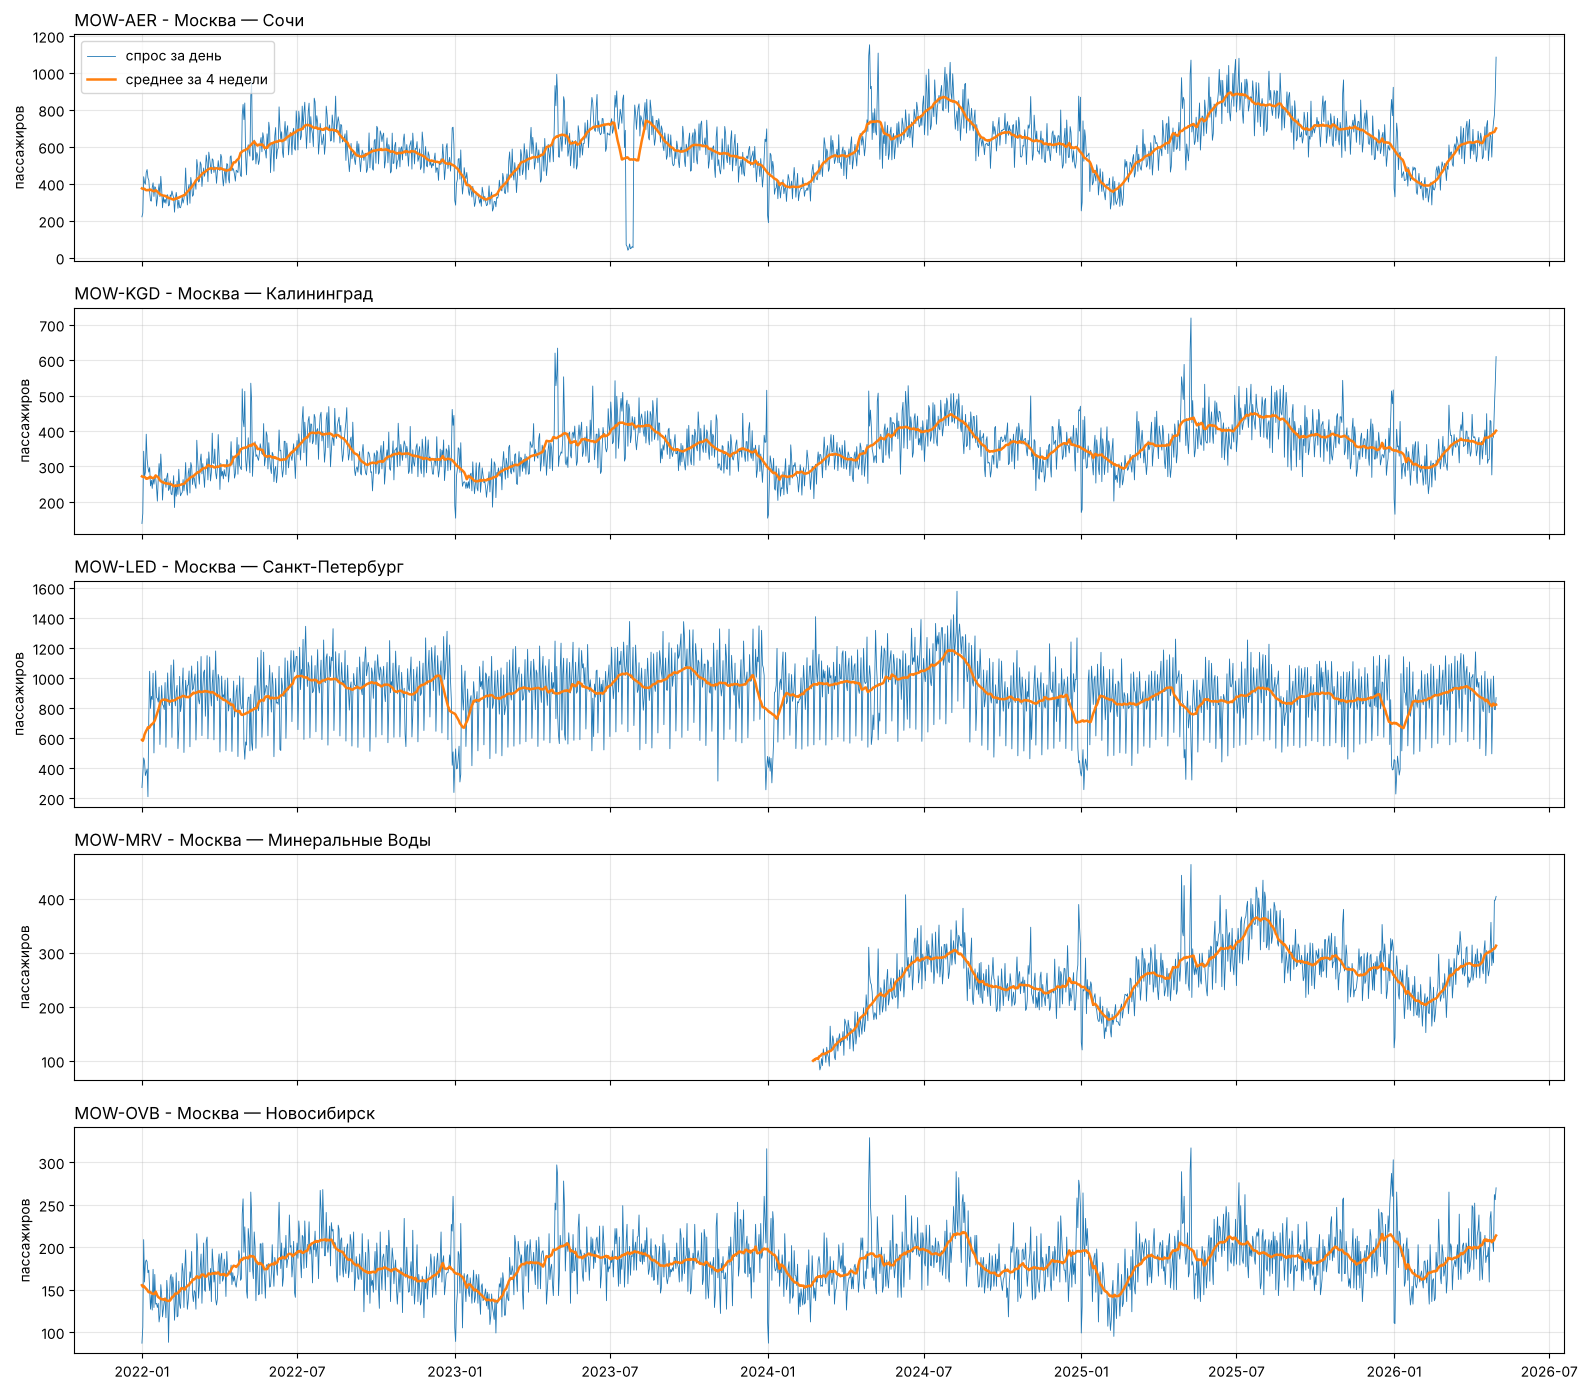

In [4]:
# Ваш код здесь
# 1.1. Спрос по датам для каждого маршрута
route_names = routes.set_index("route")["name"]
wide = train.pivot(index="date", columns="route", values="demand")   # строки - даты, столбцы - маршруты

fig, axes = plt.subplots(len(wide.columns), 1, figsize=(16, 2.8 * len(wide.columns)), sharex=True)
for ax, r in zip(axes, wide.columns):
    ax.plot(wide.index, wide[r], lw=0.6, label="спрос за день")
    ax.plot(wide.index, wide[r].rolling(28, center=True, min_periods=7).mean(), lw=1.8, color="C1",
            label="среднее за 4 недели")
    ax.set_title(f"{r} - {route_names[r]}", loc="left")
    ax.set_ylabel("пассажиров")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

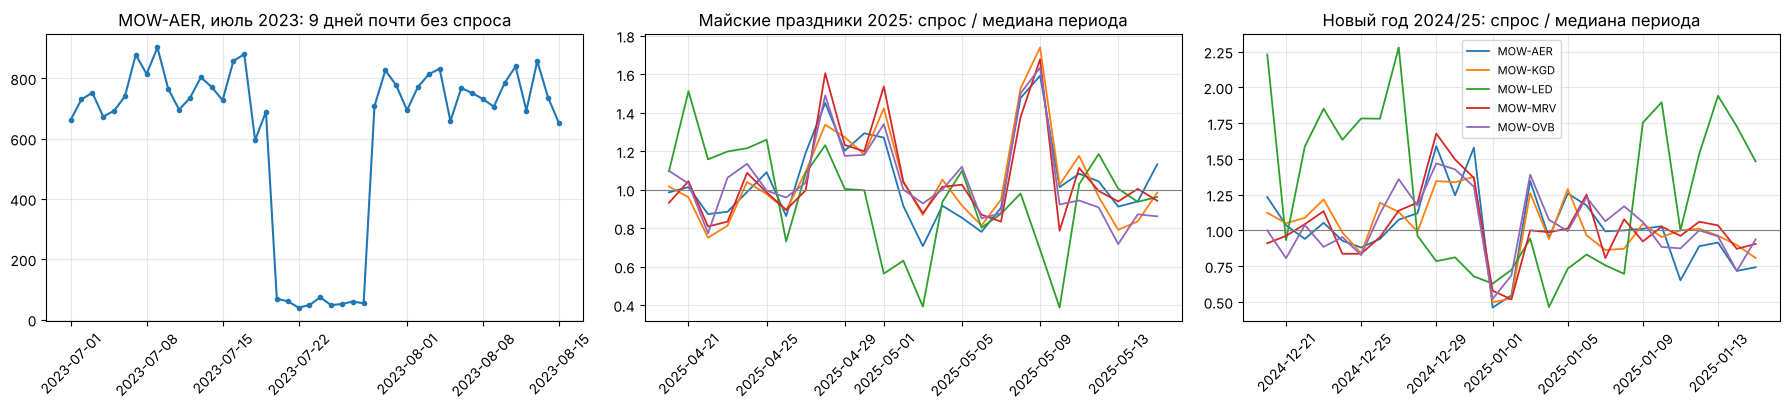

Спрос в дату / обычный спрос (1.00 - как обычно):


date,12-28,12-29,12-30,12-31,01-01,01-02,01-03,01-08,02-22,02-23,...,05-01,05-02,05-08,05-09,05-10,06-10,06-11,06-12,11-03,11-04
route,,,,,,,,,,,,,,,,,,,,,
"туристические (AER, KGD, MRV, OVB)",1.21,1.30,1.40,1.52,0.58,0.57,1.09,1.21,1.08,0.96,...,1.39,0.99,1.36,1.50,1.02,1.22,1.23,1.04,1.24,1.00
MOW-LED,1.03,0.43,0.45,0.45,0.49,0.44,0.46,0.46,0.99,1.03,...,0.59,0.59,1.01,0.61,0.64,0.94,0.94,0.65,0.99,0.59


Недельная сезонность: средний спрос в день недели / средний спрос


,пн,вт,ср,чт,пт,сб,вс
route,,,,,,,
MOW-AER,1.05,0.88,0.93,1.05,1.08,0.92,1.09
MOW-KGD,1.04,0.89,0.92,1.06,1.08,0.92,1.09
MOW-LED,1.20,1.00,0.98,1.05,1.18,0.62,0.97
MOW-MRV,1.06,0.90,0.94,1.06,1.07,0.91,1.06
MOW-OVB,1.05,0.88,0.93,1.07,1.08,0.91,1.08


Начало истории по маршрутам:


route
MOW-AER   2022-01-01
MOW-KGD   2022-01-01
MOW-LED   2022-01-01
MOW-MRV   2024-03-01
MOW-OVB   2022-01-01
Name: date, dtype: datetime64[ns]

In [5]:
# 1.2. Приглядимся к необычным местам
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
w = wide.loc["2023-07-01":"2023-08-15", "MOW-AER"]
axes[0].plot(w.index, w, marker=".")
axes[0].set_title("MOW-AER, июль 2023: 9 дней почти без спроса")
for ax, (start, end, title) in zip(axes[1:], [("2025-04-20", "2025-05-15", "Майские праздники 2025"),
                                               ("2024-12-20", "2025-01-15", "Новый год 2024/25")]):
    w = wide.loc[start:end]
    for r in w.columns:
        ax.plot(w.index, w[r] / w[r].median(), label=r, lw=1.3)
    ax.axhline(1, color="gray", lw=0.8)
    ax.set_title(f"{title}: спрос / медиана периода")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Во сколько раз спрос в календарную дату отличается от «обычного»: делим на медиану того же дня недели
# в соседние ±4 недели и усредняем по годам 2022-2026.
def ratio_to_usual(s):
    out = pd.Series(np.nan, index=s.index)
    for dow in range(7):
        same_dow = s[s.index.dayofweek == dow]
        out.loc[same_dow.index] = same_dow / same_dow.rolling(9, center=True, min_periods=3).median()
    return out

ratios = wide.apply(ratio_to_usual)
ratios.loc["2023-07-20":"2023-07-28", "MOW-AER"] = np.nan          # разовый провал не усредняем
by_day = ratios.groupby(ratios.index.strftime("%m-%d")).mean()
by_day["туристические (AER, KGD, MRV, OVB)"] = by_day[["MOW-AER", "MOW-KGD", "MOW-MRV", "MOW-OVB"]].mean(axis=1)
key_days = ["12-28", "12-29", "12-30", "12-31", "01-01", "01-02", "01-03", "01-08", "02-22", "02-23", "03-07",
            "03-08", "04-28", "04-29", "04-30", "05-01", "05-02", "05-08", "05-09", "05-10", "06-10", "06-11",
            "06-12", "11-03", "11-04"]
print("Спрос в дату / обычный спрос (1.00 - как обычно):")
display(by_day.loc[key_days, ["туристические (AER, KGD, MRV, OVB)", "MOW-LED"]].round(2).T)

print("Недельная сезонность: средний спрос в день недели / средний спрос")
dow = wide.groupby(wide.index.dayofweek).mean() / wide.mean()
dow.index = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]
display(dow.round(2).T)
print("Начало истории по маршрутам:")
display(train.groupby("route")["date"].min())

**Ваш ответ:** Что необычного вы нашли в данных? Это шум или что-то полезное для модели? Что, по-вашему, происходило в эти дни?

1. **Тренд и годовая сезонность.** На направлениях Сочи, Калининград, Минеральные Воды и Новосибирск (дальше - «туристические», в отличие от делового Петербурга) летом пик, в январе-феврале провал, и спрос растёт из года в год (Сочи: средний июньский спрос 639 → 707 → 714 → 859 в 2022-2025). У Москвы - Петербурга годовой сезонности почти нет.
2. **Недельная сезонность.** Сильнее всего на MOW-LED: в субботу спрос всего 0.62 от среднего, в понедельник и пятницу - 1.18-1.20. Это деловое направление: командировки начинаются в понедельник и заканчиваются в пятницу. На туристических маршрутах выше пятница и воскресенье (~1.08), ниже вторник, среда и суббота (~0.9).
3. **Праздники - резкие скачки, которые повторяются каждый год в одни и те же даты.** На туристических маршрутах спрос растёт перед длинными выходными: 28-31 декабря (×1.2-1.5), 28 апреля - 1 мая (×1.4-1.5), 8-9 мая (×1.4-1.5), 10-11 июня (×1.2), 2-3 ноября (×1.2), 6-7 марта и 21-22 февраля (×1.1-1.15) - люди улетают отдыхать. 1-2 января спрос почти вдвое ниже обычного: все празднуют. На Москве - Петербурге наоборот: в нерабочие праздники (29 декабря - 8 января, 1-3 и 9-10 мая, 12 июня, 4 ноября) спрос падает до 0.43-0.65 от обычного - командировок нет. **Это полезный сигнал, а не шум**: даты праздников известны заранее, и их можно передать модели как признаки (задание 3).
4. **Провал MOW-AER 20-28 июля 2023**: девять дней спрос 40-75 человек вместо обычных 700-850, затем мгновенный возврат к норме. В другие годы такого нет, другие маршруты не затронуты - похоже на закрытие аэропорта Сочи или ограничение полётов, а не на падение интереса к поездкам. **Это шум**: разовое событие, которое нельзя предсказать по календарю. Если его оставить, модели будут переносить «провал» на июль следующих лет и занижать прогноз. Поэтому перед обучением заменяю эти дни средним того же дня недели за две недели до и после.
5. **Новый маршрут MOW-MRV** появился только 1 марта 2024 года, и в первые месяцы спрос рос примерно с 90 до 300 человек в день - направление «раскручивалось». Ряд короче остальных, своих примеров сезонности у него мало; помогают глобальные модели, которые учатся сразу на всех маршрутах.
6. Всплеск в самом конце train (28-30 апреля 2026) - не аномалия, а тот же предпраздничный эффект перед майскими.

## Задание 2. Обучение моделей в AutoGluon

[AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/index.html) - библиотека, которая умеет обучать сразу много
моделей прогнозирования временных рядов и сравнивать их между собой. Подробнее - в
[быстром старте](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-quick-start.html).

Шпаргалка по основным вызовам (из документации AutoGluon):

```python
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# 1) данные: длинная таблица - по строке на каждый ряд и момент времени
data = TimeSeriesDataFrame.from_data_frame(df, id_column="item_id", timestamp_column="timestamp")

# 2) предиктор
predictor = TimeSeriesPredictor(
    prediction_length=48,              # на сколько шагов вперёд прогнозировать
    target="target",                   # какую колонку прогнозируем
    eval_metric="MASE",                # как считаем ошибку
    quantile_levels=[0.1, 0.5, 0.9],   # какие квантили выдавать
    path="autogluon-models",           # куда сохранять модели
)

# 3а) обучение готовым набором моделей - пресетом
predictor.fit(data, presets="medium_quality", time_limit=600)

# 3б) или списком конкретных моделей с параметрами
predictor.fit(data, hyperparameters={
    "SeasonalNaive": {},
    "DirectTabular": {},
    "Chronos": {"model_path": "bolt_small"},
})

# 4) таблица моделей: ошибка на валидации (score_val), время обучения и прогноза
predictor.leaderboard()

# 5) прогноз и график: история + прогноз с квантилями
predictions = predictor.predict(data)
predictor.plot(data, predictions, quantile_levels=[0.1, 0.9], max_history_length=200)

# 6) ошибка на тестовых данных (история + последние prediction_length шагов для проверки)
predictor.evaluate(test_data)
```

На что обратить внимание:
- **Длина прогноза.** Выберите её сами, исходя из длины тестовых данных.
- **Метрика.** Ошибку считаем по **MAE** (средняя абсолютная ошибка: на сколько пассажиров в среднем промахивается прогноз).
- **Квантили.** Модель должна выдавать квантили от 0.1 до 0.9: из них потом получится распределение цены.
- **Валидация.** AutoGluon сам откладывает последние дни обучающих данных как валидацию и сравнивает модели по ним.
  Тест (`test.csv`) пока **не трогаем**: он понадобится в самом конце.
- **Какие модели обучать.** Пресет - быстрый способ начать; список моделей и параметров даёт больше контроля.
  Какие есть пресеты и модели, смотрите в
  [описании моделей](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-model-zoo.html).

**2.1.** Обучите модели на `train`. Поэкспериментируйте с разными конфигурациями обучения (пресеты, наборы моделей,
их параметры) и выберите **конфигурацию**, которая даёт наименьшую ошибку на валидации.

**2.2.** Посмотрите на таблицу моделей (`leaderboard`) для выбранной конфигурации. Какая модель лучшая по валидации?
Как вы думаете, почему именно, как она работает? Насколько она лучше самой простой - `SeasonalNaive` (как в прошлом сезоне)?

**Результат задания:** обученные модели и таблица моделей (`leaderboard`) для лучшей конфигурации; текстовый ответ: какие
конфигурации вы пробовали, какая модель лучшая по валидации и почему, насколько она лучше `SeasonalNaive`.

In [6]:
# Ваш код здесь
# Результат: обученный predictor и таблица results_v1 = predictor.leaderboard()
# test пока не используем
import time
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

PREDICTION_LENGTH = test["date"].nunique()   # 31 день: тест - весь май; сервису нужен прогноз на 1 июня - 1 июля (тоже 31 день)
QUANTILE_LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
NUM_VAL_WINDOWS = 3     # валидация на трёх последних 31-дневных окнах train (февраль-апрель 2026): надёжнее одного месяца
print("Длина прогноза:", PREDICTION_LENGTH, "дней")

def clean_outliers(df):
    """Разовый провал MOW-AER 20-28.07.2023 (задание 1) заменяем средним того же дня недели за 2 недели до и после."""
    df = df.copy()
    s = df.set_index(["route", "date"])["demand"]
    bad = (df["route"] == "MOW-AER") & df["date"].between("2023-07-20", "2023-07-28")
    two_weeks = pd.Timedelta(days=14)
    df.loc[bad, "demand"] = [round((s[("MOW-AER", d - two_weeks)] + s[("MOW-AER", d + two_weeks)]) / 2)
                             for d in df.loc[bad, "date"]]
    return df

train_clean = clean_outliers(train)
train_ts = TimeSeriesDataFrame.from_data_frame(train_clean, id_column="route", timestamp_column="date")

def make_predictor(name, **kwargs):
    return TimeSeriesPredictor(prediction_length=PREDICTION_LENGTH, target="demand", eval_metric="MAE",
                               quantile_levels=QUANTILE_LEVELS, path=f"autogluon-models/{name}", verbosity=1, **kwargs)

CONFIGS = {
    # пресет: SeasonalNaive, ETS, Theta, RecursiveTabular, DirectTabular, Chronos-2 small, Toto-2 + ансамбль
    "medium_quality": dict(presets="medium_quality"),
    # пресет: + AutoETS, DynamicOptimizedTheta, TFT, DeepAR, Chronos-2 base, дообученный Chronos-2 small, Toto-2 22m
    "high_quality": dict(presets="high_quality"),
    # свой набор: две версии Chronos-2 (small и base), табличные модели (общая и по шагу горизонта) и простые бейзлайны
    "custom": dict(hyperparameters={
        "SeasonalNaive": {}, "Theta": {}, "DirectTabular": {}, "PerStepTabular": {},
        "Chronos2": [{"model_path": "autogluon/chronos-2-small"},
                     {"model_path": "autogluon/chronos-2", "ag_args": {"name_suffix": "Base"}}],
    }),
}

predictors, summary = {}, []
for name, fit_kwargs in CONFIGS.items():
    p = make_predictor(f"v1_{name}")
    t0 = time.time()
    p.fit(train_ts, num_val_windows=NUM_VAL_WINDOWS, time_limit=1800, **fit_kwargs)
    lb = p.leaderboard()
    predictors[name] = p
    summary.append({"конфигурация": name, "лучшая модель": lb.iloc[0]["model"],
                    "MAE на валидации": round(-lb.iloc[0]["score_val"], 2),
                    "MAE SeasonalNaive": round(-lb.set_index("model").loc["SeasonalNaive", "score_val"], 2),
                    "моделей": len(lb), "время обучения, с": round(time.time() - t0)})
summary = pd.DataFrame(summary).sort_values(["MAE на валидации", "время обучения, с"]).reset_index(drop=True)
display(summary)

BEST_CONFIG = summary.loc[0, "конфигурация"]
predictor = predictors[BEST_CONFIG]
results_v1 = predictor.leaderboard()
print("Лучшая конфигурация:", BEST_CONFIG)
display(results_v1)

mae_v1 = -results_v1.set_index("model")["score_val"]
best_v1 = results_v1.iloc[0]["model"]
print(f"Лучшая модель {best_v1}: MAE = {mae_v1[best_v1]:.1f} пасс.; SeasonalNaive: MAE = {mae_v1['SeasonalNaive']:.1f} пасс. "
      f"-> ошибка меньше на {1 - mae_v1[best_v1] / mae_v1['SeasonalNaive']:.0%}")
try:
    print("Веса ансамбля:", predictor._trainer.load_model("WeightedEnsemble").model_to_weight)
except Exception:
    pass

Длина прогноза: 31 дней


,конфигурация,лучшая модель,MAE на валидации,MAE SeasonalNaive,моделей,"время обучения, с"
0,high_quality,WeightedEnsemble,34.35,51.54,11,1086
1,medium_quality,WeightedEnsemble,35.43,51.54,8,19
2,custom,WeightedEnsemble,35.44,51.54,7,168


Лучшая конфигурация: high_quality


,model,score_val,pred_time_val,fit_time_marginal,fit_order
0,WeightedEnsemble,-34.351539,0.455534,0.497570,11
1,TemporalFusionTransformer,-36.584366,0.012538,466.539696,9
2,Chronos2,-36.700148,0.393064,2.486336,5
3,DirectTabular,-38.158118,0.048967,3.784781,3
4,Chronos2SmallFineTuned,-38.408110,0.352861,286.409802,6
5,DeepAR,-38.895465,0.115590,293.778574,10
6,Toto2,-41.286522,0.071246,1.192246,8
7,RecursiveTabular,-47.636469,0.098839,4.331084,2
8,AutoETS,-48.124929,0.880072,1.620669,7
9,DynamicOptimizedTheta,-49.138821,8.303974,15.224776,4


Лучшая модель WeightedEnsemble: MAE = 34.4 пасс.; SeasonalNaive: MAE = 51.5 пасс. -> ошибка меньше на 33%
Веса ансамбля: {'Chronos2': 0.25773195876288657, 'TemporalFusionTransformer': 0.4536082474226804, 'DirectTabular': 0.28865979381443296}


**Ваш ответ:** Какие конфигурации вы пробовали? Какая модель лучшая по валидации? Почему именно она, как она работает? Насколько она лучше SeasonalNaive?

Во всех конфигурациях одинаковые настройки: прогноз на 31 день (как длина теста и как нужный сервису период), метрика MAE, квантили 0.1-0.9, **3 окна валидации** (февраль, март и апрель 2026) - так ошибка не зависит от особенностей одного месяца.

| конфигурация | что внутри | лучший MAE на валидации | время обучения |
|---|---|---|---|
| `high_quality` | 11 моделей: + нейросети TFT и DeepAR, Chronos-2 base, дообученный Chronos-2 small | **34.35** | ~18 мин |
| `medium_quality` | 8 моделей: SeasonalNaive, ETS, Theta, RecursiveTabular, DirectTabular, Chronos-2 small, Toto-2 | 35.43 | 19 с |
| свой набор | Chronos-2 small и base, DirectTabular, PerStepTabular, Theta, SeasonalNaive | 35.44 | ~3 мин |

Лучшая конфигурация по валидации - `high_quality`, лучшая модель в ней - **WeightedEnsemble** (MAE 34.35). Это взвешенное среднее прогнозов нескольких моделей: 0.45 × TemporalFusionTransformer + 0.29 × DirectTabular + 0.26 × Chronos-2. Веса подбираются жадно, чтобы ошибка среднего на валидации была минимальной. Ансамбль выигрывает, потому что модели устроены по-разному и ошибаются в разных местах, а при усреднении ошибки частично гасят друг друга:
- **Chronos-2** - предобученная «фундаментальная» модель (трансформер), которую заранее обучили на огромном числе чужих временных рядов. Нашу историю она получает как контекст и сразу выдаёт квантили, без обучения на наших данных; хорошо ловит уровень, тренд и сезонность;
- **DirectTabular** - градиентный бустинг (LightGBM) на лагах и календарных признаках, напрямую прогнозирует каждый шаг горизонта; хорошо ловит недельный ритм и календарь;
- **TFT** - нейросеть-трансформер, обученная с нуля на наших пяти рядах.

**По сравнению с SeasonalNaive** (MAE 51.54) ошибка лучшей модели меньше на **33%** (34.35 против 51.54 пассажира). SeasonalNaive просто повторяет значения недельной давности: он не видит ни тренда, ни годовой сезонности, ни праздников - и, например, переносит предпраздничный всплеск на неделю позже.

Наблюдение для задания 4: `high_quality` лучше `medium_quality` всего на 3%, но обучается в 57 раз дольше. И нейросети нестабильны: они обучаются с ограничением по времени на CPU, и та же TFT в задании 3 дала MAE 62 вместо 37.

## Задание 3. Признаки: помогаем модели

Кроме истории наблюдений, у нас могут быть **дополнительные данные** о будущих днях, которые помогают прогнозу. Например:
- прогноз погоды;
- расписание крупных событий (концерты, спортивные матчи, фестивали);
- школьные каникулы;
- акции и распродажи, которые мы сами планируем.

Их можно передать модели как **признаки**. В AutoGluon они называются `known_covariates`, то есть признаки, известные
заранее: их значения должны быть известны и для будущих дат, на которые мы строим прогноз.

В наших данных таких дополнительных колонок нет, есть только даты. Но и из дат можно кое-что извлечь. Вспомните, что
необычного вы нашли в задании 1: некоторые скачки и провалы повторяются **каждый год в одни и те же даты**. Что это за
дни и можно ли знать их заранее?

**3.1.** Придумайте признаки, которые можно получить из даты, и напишите функцию **`add_features(df)`**, которая
добавляет их в таблицу с колонкой `date`.

Пример, как устроена такая функция (признак здесь просто для иллюстрации):

```python
def add_features(df):
    df = df.copy()
    month = df["date"].dt.month_name()     # название месяца по-английски: "January" … "December"
    day = df["date"].dt.day                # число месяца: 1–31

    # признак 1 сентября: 1 в этот день, иначе 0; условия объединяются через & (и) и | (или)
    df["sept_1"] = ((month == "September") & (day == 1)).astype(int)

    return df
```

**3.2.** Обучите модели заново с вашими признаками и сравните ошибку **на валидации** с заданием 2. Помогли ли признаки?
Каким моделям больше, каким меньше и почему? Сохраните таблицу моделей в **`results_v2`**.

Подсказки по AutoGluon:
- при создании предиктора укажите `known_covariates_names=[...]` - список названий ваших признаков;
- признаки должны быть в данных для обучения **и** для будущих дат: при прогнозе их передают через
  `predictor.predict(data, known_covariates=...)`;
- день недели и день года AutoGluon добавляет сам - их придумывать не нужно.

**Результат задания:** функция `add_features(df)`, модели, обученные с признаками, и сравнение ошибки на валидации
с заданием 2; текстовый ответ: какие признаки вы придумали и почему, помогли ли они и каким моделям.

In [7]:
# Ваш код здесь
# Результат: функция add_features(df), обученный predictor с признаками, таблица results_v2

# Повторяющиеся каждый год даты из задания 1. Это календарь - он известен заранее на любые будущие даты.
PRE_HOLIDAY_DAYS = ["12-28", "12-29", "12-30", "12-31", "02-21", "02-22", "03-06", "03-07", "04-28", "04-29",
                    "04-30", "05-01", "05-08", "05-09", "06-10", "06-11", "11-02", "11-03"]
HOLIDAY_DAYS = ["12-29", "12-30", "12-31"] + [f"01-0{d}" for d in range(1, 9)] + \
               ["05-01", "05-02", "05-03", "05-09", "05-10", "06-12", "11-04"]
NEW_YEAR_DAYS = ["01-01", "01-02"]
FEATURES = ["pre_holiday", "holiday", "new_year"]

def add_features(df):
    df = df.copy()
    md = df["date"].dt.strftime("%m-%d")                         # месяц-день, например "05-09"
    df["pre_holiday"] = md.isin(PRE_HOLIDAY_DAYS).astype(int)    # перед длинными выходными: все улетают отдыхать
    df["holiday"] = md.isin(HOLIDAY_DAYS).astype(int)            # нерабочие праздники: деловые поездки замирают
    df["new_year"] = md.isin(NEW_YEAR_DAYS).astype(int)          # 1-2 января почти никто не летит
    return df

# Статический признак маршрута (не меняется во времени): Москва - Петербург - деловое направление,
# на праздники спрос на нём падает, а на остальных, туристических, - растёт.
STATIC = pd.DataFrame({"route": routes["route"], "business_route": (routes["route"] == "MOW-LED").astype(int)})

def to_ts(df):
    return TimeSeriesDataFrame.from_data_frame(add_features(df), id_column="route", timestamp_column="date",
                                               static_features_df=STATIC.copy())   # copy: AutoGluon переименовывает колонку на месте

def future_covariates(dates, route_ids):
    """Признаки на будущие даты для каждого маршрута (known_covariates для predict)."""
    future = pd.DataFrame([(r, d) for r in route_ids for d in dates], columns=["route", "date"])
    return TimeSeriesDataFrame.from_data_frame(add_features(future), id_column="route", timestamp_column="date")

train_feat_ts = to_ts(train_clean)
print("Признаки вокруг майских праздников 2025, MOW-AER:")
example = add_features(train_clean)
display(example[(example["route"] == "MOW-AER") & example["date"].between("2025-04-26", "2025-05-11")]
        .set_index("date")[["demand"] + FEATURES].T)

predictor_v2 = make_predictor(f"v2_{BEST_CONFIG}", known_covariates_names=FEATURES)
predictor_v2.fit(train_feat_ts, num_val_windows=NUM_VAL_WINDOWS, time_limit=1800, **CONFIGS[BEST_CONFIG])
results_v2 = predictor_v2.leaderboard()
display(results_v2)

compare = pd.DataFrame({"MAE без признаков (v1)": -results_v1.set_index("model")["score_val"],
                        "MAE с признаками (v2)": -results_v2.set_index("model")["score_val"]})
compare["изменение, %"] = (compare["MAE с признаками (v2)"] / compare["MAE без признаков (v1)"] - 1) * 100
compare.sort_values("MAE с признаками (v2)").round(2)

Признаки вокруг майских праздников 2025, MOW-AER:


date,2025-04-26,2025-04-27,2025-04-28,2025-04-29,2025-04-30,2025-05-01,2025-05-02,2025-05-03,2025-05-04,2025-05-05,2025-05-06,2025-05-07,2025-05-08,2025-05-09,2025-05-10,2025-05-11
demand,579,800,974,807,868,853,614,474,615,573,524,608,991,1069,680,727
pre_holiday,0,0,1,1,1,1,0,0,0,0,0,0,1,1,0,0
holiday,0,0,0,0,0,1,1,1,0,0,0,0,0,1,1,0
new_year,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,model,score_val,pred_time_val,fit_time_marginal,fit_order
0,WeightedEnsemble,-33.850783,2.161430,0.509107,11
1,DirectTabular,-35.577848,0.045948,4.015529,3
2,Chronos2SmallFineTuned,-35.975387,0.974880,285.320709,6
3,Chronos2,-36.518529,0.988995,3.750185,5
4,Toto2,-41.286522,0.067447,0.878824,8
5,RecursiveTabular,-45.022935,0.112374,4.921215,2
6,AutoETS,-48.124929,0.533859,1.108623,7
7,DynamicOptimizedTheta,-49.138821,7.675675,14.577715,4
8,DeepAR,-51.444960,0.123227,313.645242,10
9,SeasonalNaive,-51.539785,0.017633,0.084066,1


,MAE без признаков (v1),MAE с признаками (v2),"изменение, %"
model,,,
WeightedEnsemble,34.35,33.85,-1.46
DirectTabular,38.16,35.58,-6.76
Chronos2SmallFineTuned,38.41,35.98,-6.33
Chronos2,36.70,36.52,-0.49
Toto2,41.29,41.29,0.00
RecursiveTabular,47.64,45.02,-5.49
AutoETS,48.12,48.12,0.00
DynamicOptimizedTheta,49.14,49.14,0.00
DeepAR,38.90,51.44,32.26


**Ваш ответ:** Какие признаки вы придумали и почему? Помогли ли они? Каким моделям больше, каким меньше и почему?

**Признаки** (по находкам задания 1 - эффекты повторяются каждый год в одни и те же даты, значит, известны заранее):
- `pre_holiday` - дни перед длинными выходными, когда все улетают отдыхать: 28-31 декабря, 21-22 февраля, 6-7 марта, 28 апреля - 1 мая, 8-9 мая, 10-11 июня, 2-3 ноября;
- `holiday` - нерабочие праздники, когда замирают деловые поездки: 29 декабря - 8 января, 1-3 и 9-10 мая, 12 июня, 4 ноября;
- `new_year` - 1-2 января, когда почти никто не летит;
- статический признак маршрута `business_route` (1 у Москвы - Петербурга): один и тот же праздник влияет на маршруты в разные стороны - на туристических спрос растёт, на деловом падает. Без этого признака модели пришлось бы усреднять противоположные эффекты.

День недели и день года AutoGluon добавляет сам.

**Результат на валидации:** ансамбль 34.35 → **33.85** (-1.5%). Помогли признаки в первую очередь моделям, которые умеют их использовать:
- табличным: DirectTabular -6.8% (38.16 → 35.58), RecursiveTabular -5.5%. Признаки напрямую попадают в деревья решений, и модель выучивает правила вида «перед праздником на туристическом маршруте спрос ×1.4»;
- дообученному Chronos-2 small: -6.3% (38.41 → 35.98). При дообучении он научился использовать признаки, а исходный Chronos-2 без обучения получил их только как контекст и выиграл мало (-0.5%);
- SeasonalNaive, AutoETS, DynamicOptimizedTheta, Toto-2 - без изменений: это одномерные модели, они смотрят только на историю спроса и признаки игнорируют;
- нейросети TFT (36.58 → 62.21) и DeepAR (38.90 → 51.44) стали хуже: они обучаются с нуля на пяти рядах с ограничением по времени на CPU, и лишние входы им не помогли успеть обучиться. Это скорее нестабильность нейросетей, чем вред признаков (табличные модели с теми же признаками стали лучше).

Выигрыш на валидации умеренный, потому что в окнах февраль-апрель праздничных дней мало (21-23 февраля, 6-8 марта, 28-30 апреля). Май и июнь, на которые мы прогнозируем, праздниками насыщены сильнее - там признаки важнее (см. задания 5 и 6).

## Задание 4. Выберите модель для бизнеса

Самая точная модель - не всегда лучшая для бизнеса. Посмотрите на `results_v2`: ошибку на валидации (`score_val`),
время обучения (`fit_time_marginal`) и время прогноза (`pred_time_val`).

**4.1.** Какая модель даёт лучшее соотношение **качество / скорость**? Посмотрите, сколько времени модели обучаются
и строят прогноз. Возможно, есть модель, которая немного уступает самой точной по качеству, но работает заметно быстрее.

**4.2.** Какую модель вы предложите авиакомпании и почему? Учтите, насколько быстро модель обучается и строит прогноз.
Запишите выбор в **`final_model`** (название модели).

**Результат задания:** выбранная модель в переменной `final_model`; текстовый ответ: почему вы выбрали именно её с учётом
качества и скорости.

,model,fit_time_marginal,pred_time_val,MAE,"хуже лучшей, %","полное время обучения, с"
0,WeightedEnsemble,0.509,2.161,33.851,0.000,1101.297
1,DirectTabular,4.016,0.046,35.578,5.102,4.016
2,Chronos2SmallFineTuned,285.321,0.975,35.975,6.276,285.321
3,Chronos2,3.750,0.989,36.519,7.881,3.750
4,Toto2,0.879,0.067,41.287,21.966,0.879
5,RecursiveTabular,4.921,0.112,45.023,33.004,4.921
6,AutoETS,1.109,0.534,48.125,42.168,1.109
7,DynamicOptimizedTheta,14.578,7.676,49.139,45.163,14.578
8,DeepAR,313.645,0.123,51.445,51.976,313.645
9,SeasonalNaive,0.084,0.018,51.540,52.256,0.084


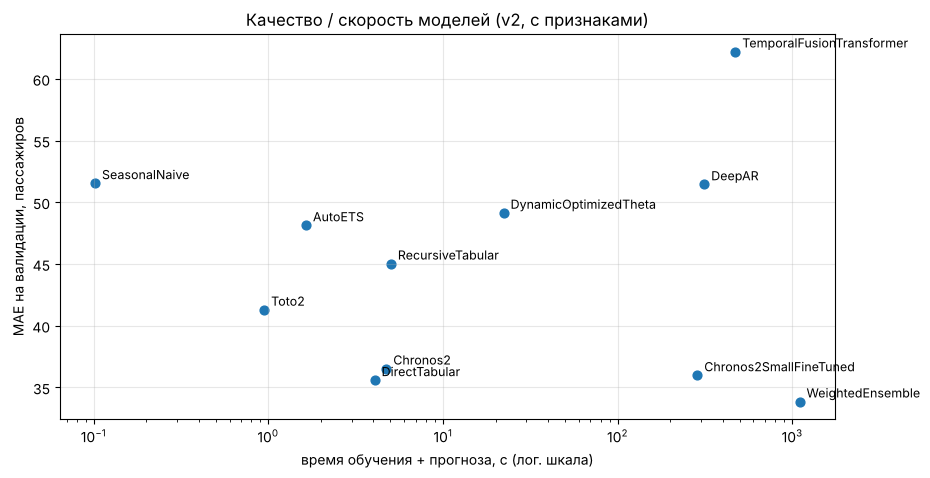

Модели в пределах 10% от лучшей по MAE:


,model,MAE,"хуже лучшей, %",WQL,покрытие 0.1-0.9,ширина интервала / медиана,"время, с",подходит по квантилям
0,WeightedEnsemble,33.851,0.000,0.081,0.974,0.633,1103.458,False
1,DirectTabular,35.578,5.102,0.109,1.000,0.996,4.061,False
2,Chronos2SmallFineTuned,35.975,6.276,0.070,0.755,0.252,286.296,True
3,Chronos2,36.519,7.881,0.073,0.710,0.274,4.739,True


final_model = Chronos2


In [8]:
# Ваш код здесь
# Например: final_model = "SeasonalNaive"
board = results_v2[["model", "score_val", "fit_time_marginal", "pred_time_val"]].copy()
board["MAE"] = -board["score_val"]
board["хуже лучшей, %"] = (board["MAE"] / board["MAE"].min() - 1) * 100
# Ансамблю для работы нужны все базовые модели: его полное время обучения - сумма времени всех моделей
board["полное время обучения, с"] = board["fit_time_marginal"]
board.loc[board["model"] == "WeightedEnsemble", "полное время обучения, с"] = board["fit_time_marginal"].sum()
board = board.drop(columns="score_val").sort_values("MAE").reset_index(drop=True)
display(board.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(board["полное время обучения, с"] + board["pred_time_val"], board["MAE"], s=40)
for _, row in board.iterrows():
    ax.annotate(row["model"], (row["полное время обучения, с"] + row["pred_time_val"], row["MAE"]),
                textcoords="offset points", xytext=(5, 3), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("время обучения + прогноза, с (лог. шкала)")
ax.set_ylabel("MAE на валидации, пассажиров")
ax.set_title("Качество / скорость моделей (v2, с признаками)")
ax.grid(alpha=0.3)
plt.show()

# Сервису нужна не только медиана, но и сценарии 0.1-0.9: из них считается распределение цены (задание 7).
# Поэтому проверяем и качество квантилей - на последнем окне валидации (апрель 2026, это часть train; тест не трогаем):
#   WQL - средняя квантильная ошибка (меньше - лучше),
#   покрытие - доля дней, когда факт попал в интервал 0.1-0.9 (в идеале около 80%), и ширина интервала.
quant = predictor_v2.leaderboard(train_feat_ts, extra_metrics=["WQL"])[["model", "WQL"]]
quant["WQL"] = -quant["WQL"]
april_hist = train_feat_ts.slice_by_timestep(None, -PREDICTION_LENGTH)
april_cov = future_covariates(pd.date_range("2026-03-31", periods=PREDICTION_LENGTH), train_feat_ts.item_ids)
def interval_quality(model):
    pr = predictor_v2.predict(april_hist, known_covariates=april_cov, model=model)
    fact_apr = train_feat_ts["demand"].loc[pr.index]
    return pd.Series({"покрытие 0.1-0.9": ((fact_apr >= pr["0.1"]) & (fact_apr <= pr["0.9"])).mean(),
                      "ширина интервала / медиана": ((pr["0.9"] - pr["0.1"]) / pr["0.5"]).mean()})

board = board.merge(quant, on="model")
board["время, с"] = board["полное время обучения, с"] + board["pred_time_val"]
# Правило выбора: среди моделей, которые уступают лучшей не больше чем на 10% и по MAE, и по WQL, берём самую быструю.
# 10% от MAE - это 3-4 пассажира на рейс в день: меньше 1% спроса и намного меньше ширины интервала прогноза.
TOLERANCE = 0.10
close = board[board["MAE"] <= board["MAE"].min() * (1 + TOLERANCE)].copy()
close = close.join(close["model"].apply(interval_quality))
close["подходит по квантилям"] = close["WQL"] <= board["WQL"].min() * (1 + TOLERANCE)
print("Модели в пределах 10% от лучшей по MAE:")
display(close[["model", "MAE", "хуже лучшей, %", "WQL", "покрытие 0.1-0.9", "ширина интервала / медиана",
               "время, с", "подходит по квантилям"]].round(3))
final_model = close[close["подходит по квантилям"]].sort_values("время, с").iloc[0]["model"]
print("final_model =", final_model)

**Ваш ответ:** Какая модель даёт лучшее соотношение качество / скорость? Какую модель вы предложите авиакомпании и почему?

| модель | MAE | хуже лучшей | WQL | покрытие 0.1-0.9 | ширина интервала | время |
|---|---|---|---|---|---|---|
| WeightedEnsemble | 33.85 | - | 0.081 | 97% | 63% медианы | ~18 мин (нужны все 11 моделей) |
| DirectTabular | 35.58 | +5.1% | 0.109 | 100% | 100% медианы | 4 с |
| Chronos2SmallFineTuned | 35.98 | +6.3% | 0.070 | 76% | 25% медианы | 286 с |
| **Chronos2** | 36.52 | +7.9% | 0.073 | 71% | 27% медианы | **5 с** |

Самая точная модель - ансамбль, но чтобы его получить, нужно обучить все 11 моделей конфигурации (около 18 минут). Если смотреть только на MAE, лучшее соотношение качество/скорость у DirectTabular. Но сервису нужна не только медиана: из сценариев 0.1-0.9 считается распределение цены. У DirectTabular интервал слишком широкий - на апрельском окне он накрыл 100% дней при ширине, равной медиане, - и пессимистичный и оптимистичный сценарии получаются нереалистичными. Поэтому я дополнительно сравнил качество квантилей (WQL и покрытие интервала) на последнем окне валидации и выбирал среди моделей, которые уступают лучшей не больше 10% и по MAE, и по WQL.

**Предлагаю авиакомпании Chronos-2** (`final_model = "Chronos2"`):
- у неё лучшее соотношение качество/скорость с учётом квантилей: обучение и прогноз за 5 секунд против 18 минут у ансамбля (примерно в 230 раз быстрее);
- проигрыш в точности - 2.7 пассажира на рейс в день, то есть около 0.5% среднего спроса (~510 человек). Это намного меньше ширины интервала прогноза (±13%) и почти не влияет на цену;
- квантили качественные: WQL почти лучший, на апрельском окне интервал 0.1-0.9 накрыл 71% дней (цель - 80%) при ширине ~27% медианы, поэтому сценарии цены осмысленные;
- это одна предобученная модель, а не связка из 11: её легко обновлять каждый день, она не страдает нестабильностью нейросетей (у TFT ошибка прыгала с 37 до 62) и сразу работает на новых маршрутах с короткой историей, как MOW-MRV.

## Задание 5. Проверка выбранной модели на тесте

Валидацию и тест используют для разных целей:
- **На валидации** мы подбираем всё что угодно и сколько угодно раз: конфигурации, модели, признаки, параметры.
  Каждый раз смотрим на ошибку и выбираем лучшее.
- **На тест** мы приходим уже с **одной** выбранной моделью и один раз смотрим на её качество. Тест отвечает на вопрос:
  насколько хорошо модель будет работать на данных, которых она никогда не видела? Дальше решаем, достаточно ли нам
  такого качества для применения или нужно что-то пересмотреть.

**Подбирать что-либо по тесту плохо.** Если перебирать модели или параметры, глядя на тест, мы незаметно подгоним
решение под эти конкретные данные. Тогда ошибка на тесте окажется заниженной и перестанет честно показывать, как модель
будет работать на новых данных. По сути тест превратится во вторую валидацию, а честной проверки у нас не останется.

А теперь давайте проверим нашу модель на тесте.

**5.1.** Посчитайте ошибку (MAE) выбранной модели на тесте с помощью `predictor.evaluate(...)` из шпаргалки.
Подсказка: нужно передать историю **вместе** с тестом (`train` + `test`), а саму модель указать параметром `model=...`.

**5.2.** Сравните ошибку на тесте с ошибкой на валидации. Почему они отличаются? Устраивает ли вас такое качество
для применения в сервисе?

**Результат задания:** ошибка (MAE) выбранной модели на тесте; текстовый ответ: почему она отличается от ошибки
на валидации и устраивает ли вас такое качество.

Chronos2: MAE на валидации = 36.5, MAE на тесте (май 2026) = 40.0 пассажиров; WQL на тесте = 0.061


,MAE,средний_спрос,MAE / средний спрос,доля дней внутри 0.1-0.9
item_id,,,,
MOW-AER,57.0,750.6,7.6%,81%
MOW-KGD,33.2,431.7,7.7%,81%
MOW-LED,65.9,860.3,7.7%,77%
MOW-MRV,26.6,307.6,8.7%,87%
MOW-OVB,17.1,209.2,8.2%,84%


Общий MAE по разбору: 40.0; WAPE (MAE / средний спрос): 7.8%; факт внутри интервала 0.1-0.9 в 82% дней
MAE в праздничные 1-11 мая: 42.5; в обычные 12-31 мая: 38.6


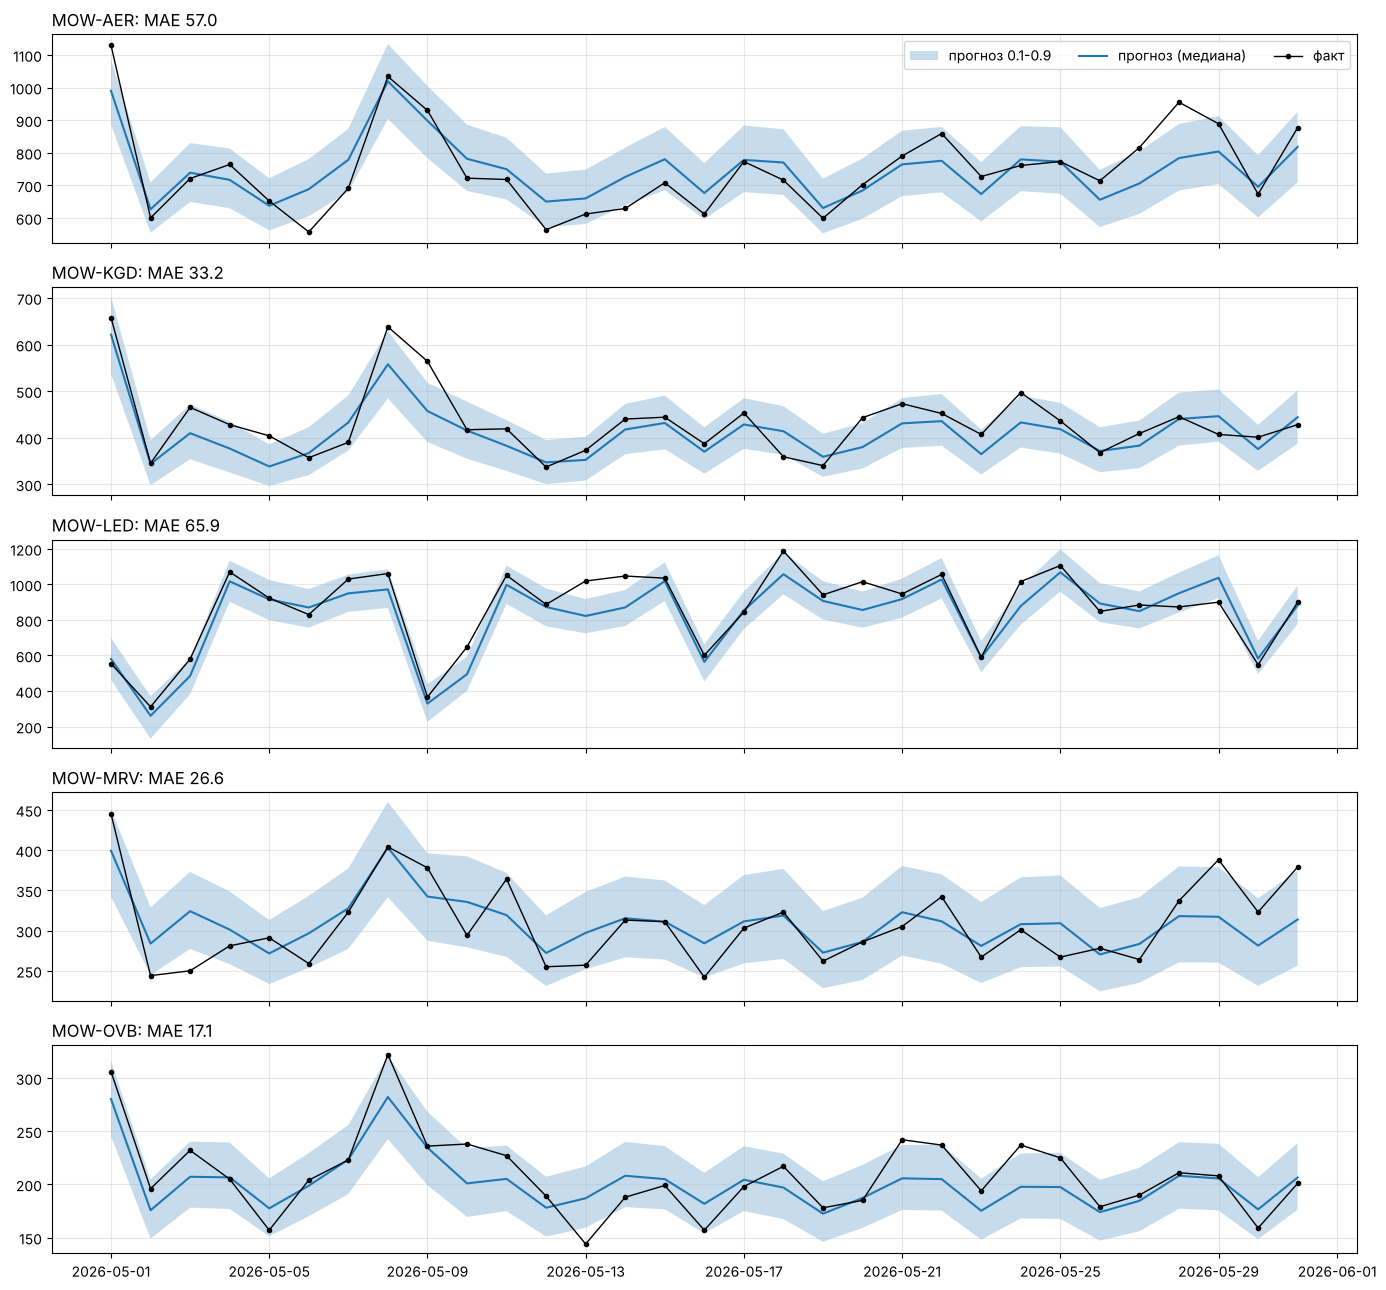

In [9]:
# Ваш код здесь
# Подсказка: predictor.evaluate(train + test с признаками, model=final_model)
full_ts = to_ts(pd.concat([train_clean, test], ignore_index=True))   # история + май (последние 31 день - тест)
test_scores = predictor_v2.evaluate(full_ts, model=final_model, metrics=["MAE", "WQL"])
test_mae = -test_scores["MAE"]
val_mae = -results_v2.set_index("model").loc[final_model, "score_val"]
print(f"{final_model}: MAE на валидации = {val_mae:.1f}, MAE на тесте (май 2026) = {test_mae:.1f} пассажиров; "
      f"WQL на тесте = {-test_scores['WQL']:.3f}")

# Разбор теста по маршрутам и по дням: тот же прогноз, что и в evaluate (история - train, признаки на май)
may_cov = future_covariates(pd.date_range("2026-05-01", periods=PREDICTION_LENGTH), train_feat_ts.item_ids)
may_pred = predictor_v2.predict(train_feat_ts, known_covariates=may_cov, model=final_model)
fact = test.set_index(["route", "date"])["demand"]
err = pd.DataFrame({"факт": [fact[(r, d)] for r, d in may_pred.index], "прогноз": may_pred["mean"].values,
                    "q0.1": may_pred["0.1"].values, "q0.9": may_pred["0.9"].values},
                   index=may_pred.index)
err["ошибка"] = (err["факт"] - err["прогноз"]).abs()
by_route = err.groupby(level=0).agg(MAE=("ошибка", "mean"), средний_спрос=("факт", "mean"))
by_route["MAE / средний спрос"] = (by_route["MAE"] / by_route["средний_спрос"]).map("{:.1%}".format)
by_route["доля дней внутри 0.1-0.9"] = err.groupby(level=0).apply(
    lambda g: ((g["факт"] >= g["q0.1"]) & (g["факт"] <= g["q0.9"])).mean()).map("{:.0%}".format)
display(by_route.round(1))
print(f"Общий MAE по разбору: {err['ошибка'].mean():.1f}; "
      f"WAPE (MAE / средний спрос): {err['ошибка'].sum() / err['факт'].sum():.1%}; "
      f"факт внутри интервала 0.1-0.9 в {((err['факт'] >= err['q0.1']) & (err['факт'] <= err['q0.9'])).mean():.0%} дней")
may_days = err.index.get_level_values("timestamp")
holiday_part = may_days <= "2026-05-11"
print(f"MAE в праздничные 1-11 мая: {err.loc[holiday_part, 'ошибка'].mean():.1f}; "
      f"в обычные 12-31 мая: {err.loc[~holiday_part, 'ошибка'].mean():.1f}")

fig, axes = plt.subplots(len(by_route), 1, figsize=(14, 2.6 * len(by_route)), sharex=True)
for ax, r in zip(axes, by_route.index):
    e = err.loc[r]
    ax.fill_between(e.index, e["q0.1"], e["q0.9"], alpha=0.25, label="прогноз 0.1-0.9")
    ax.plot(e.index, e["прогноз"], label="прогноз (медиана)")
    ax.plot(e.index, e["факт"], "k.-", lw=1, label="факт")
    ax.set_title(f"{r}: MAE {by_route.loc[r, 'MAE']:.1f}", loc="left")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right", ncol=3)
plt.tight_layout()
plt.show()

**Ваш ответ:** Почему ошибка на тесте отличается от ошибки на валидации? Устраивает ли вас такое качество для применения в сервисе?

**MAE Chronos-2 на тесте (май 2026) - 40.0 пассажира** против 36.5 на валидации (+10%); WQL на тесте 0.061.

Почему ошибка на тесте выше:
1. **Другой период.** Валидация - среднее по трём окнам февраль-апрель, а тест - один май, самый праздничный месяц: две длинные выходные (1-3 и 9-11 мая) с предпраздничными всплесками и провалами на деловом маршруте. MAE за 1-11 мая - 42.5, за 12-31 мая - 38.6.
2. **Выше уровень спроса.** К лету спрос растёт (Сочи: ~600 в апреле, 750 в мае), а абсолютная ошибка растёт вместе с уровнем. Относительная ошибка (WAPE) - 7.8%.
3. **Случайность одного месяца.** 155 точек теста - это немного, отдельные необычные дни заметно сдвигают среднее.
4. **Эффект выбора.** Конфигурацию и модель мы выбирали по валидации, поэтому её ошибка немного оптимистична. Тест, который мы не трогали, даёт честную оценку.

**Качество меня устраивает.** Ошибка на всех маршрутах примерно одинаковая в относительном выражении: 7.6-8.7% среднего спроса (17 пассажиров на Новосибирске, 66 на Петербурге). Интервал 0.1-0.9 накрыл фактический спрос в **82% дней** при идеальных 80%, то есть сценарии откалиброваны, а это важно для распределения цены. В деньгах: ошибка 57 пассажиров на Сочи соответствует сдвигу цены «полного самолёта» примерно на 400 ₽ (57 / 0.141), около 4% базовой цены. Для сервиса это приемлемо; в праздничные дни стоит дополнительно смотреть на разброс сценариев, а модель - регулярно переобучать на свежих данных.

## Задание 6. Финальный прогноз для сервиса

Модель выбрана и проверена, пора готовить прогноз, которым будет пользоваться сервис. Сервису нужен спрос
на **1 июня - 1 июля 2026**.

Перед этим модель нужно обучить заново:
- **Обучаем на всей истории.** Май уже прошёл, и тест теперь - такие же известные данные, как и остальная история.
  Чем свежее данные, тем лучше модель знает текущий уровень спроса. Поэтому обучаем на `train` + `test`.
- **С теми же настройками.** Конфигурацию, признаки и модель мы уже выбрали на валидации и проверили на тесте,
  менять их теперь нельзя: иначе проверка на тесте потеряет смысл.
- **С признаками для будущих дат.** Прогноз строится на 31 день вперёд, поэтому для каждого маршрута и каждого из этих
  дней нужно заранее посчитать ваши признаки.

А теперь давайте построим финальный прогноз.

**6.1.** Обучите модели на `train` + `test` с теми же настройками и признаками. Назовите предиктор **`predictor`**,
а данные с историей - **`history_ts`**: они понадобятся для графика ниже.

**6.2.** Подготовьте признаки на 31 будущий день (1 июня - 1 июля 2026) для каждого маршрута и постройте прогноз
выбранной моделью. Сохраните его в **`predictions`**. Подсказка: даты удобно получить через
`pd.date_range("2026-06-01", periods=31)`.

In [10]:
# Ваш код здесь
# Результат: predictor, history_ts и прогноз на июнь predictions
# 6.1. Та же конфигурация, те же признаки и та же очистка выброса - но на всей истории (train + test)
history = pd.concat([train_clean, test], ignore_index=True)
history_ts = to_ts(history)
predictor = make_predictor(f"final_{BEST_CONFIG}", known_covariates_names=FEATURES)
predictor.fit(history_ts, num_val_windows=NUM_VAL_WINDOWS, time_limit=1800, **CONFIGS[BEST_CONFIG])

# 6.2. Признаки на 31 будущий день (1 июня - 1 июля 2026) для каждого маршрута и прогноз выбранной моделью
future_dates = pd.date_range("2026-06-01", periods=31)
future_cov = future_covariates(future_dates, history_ts.item_ids)
predictions = predictor.predict(history_ts, known_covariates=future_cov, model=final_model)
predictions = predictions.clip(lower=0)            # спрос не может быть отрицательным
print("Даты прогноза:", predictions.index.get_level_values("timestamp").min().date(), "-",
      predictions.index.get_level_values("timestamp").max().date(), "| строк:", len(predictions))
print("Признаки в прогнозный период (дни, отмеченные хотя бы одним признаком):")
june = add_features(pd.DataFrame({"date": future_dates}))
display(june[june[FEATURES].sum(axis=1) > 0].set_index("date").T)
predictions.head()

Даты прогноза: 2026-06-01 - 2026-07-01 | строк: 155
Признаки в прогнозный период (дни, отмеченные хотя бы одним признаком):


date,2026-06-10,2026-06-11,2026-06-12
pre_holiday,1,1,0
holiday,0,0,1
new_year,0,0,0


mean         0.1         0.2         0.3  \
item_id timestamp                                                    
MOW-AER 2026-06-01  837.193970  765.481873  789.579712  807.793091   
        2026-06-02  732.524048  660.875122  684.340820  702.442871   
        2026-06-03  779.055664  702.501831  727.152832  745.965942   
        2026-06-04  842.420898  759.586670  787.579712  807.982727   
        2026-06-05  860.043579  776.337158  803.541016  824.663025   

                           0.4         0.5         0.6         0.7  \
item_id timestamp                                                    
MOW-AER 2026-06-01  822.047302  837.193970  851.195068  865.685303   
        2026-06-02  717.689209  732.524048  746.810608  761.495789   
        2026-06-03  762.550293  779.055664  794.344666  809.941956   
        2026-06-04  826.234619  842.420898  860.228149  876.699097   
        2026-06-05  843.249268  860.043579  878.286133  897.406250   

                           0.8         0.9  
item_id timestamp                           
MOW-AER 2026-06-01  882.628906  907.542053  
        2026-06-02  780.195740  806.003784  
        2026-06-03  829.745667  854.748657  
        2026-06-04  898.977905  928.851318  
        2026-06-05  921.540405  950.897949

**6.3.** Посмотрите на получившийся прогноз глазами: постройте график, на котором видны последние дни истории и прогноз
на июнь со сценариями от 0.1 до 0.9. Вам может помочь метод `predictor.plot(...)` из шпаргалки.

Как вам прогноз визуально? Похож ли он на то, как спрос вёл себя в истории? Почему интервал расширяется со временем?

**Результат задания:** прогноз на 1 июня - 1 июля в переменной `predictions` и график прогноза; текстовый ответ: как вам
прогноз визуально.

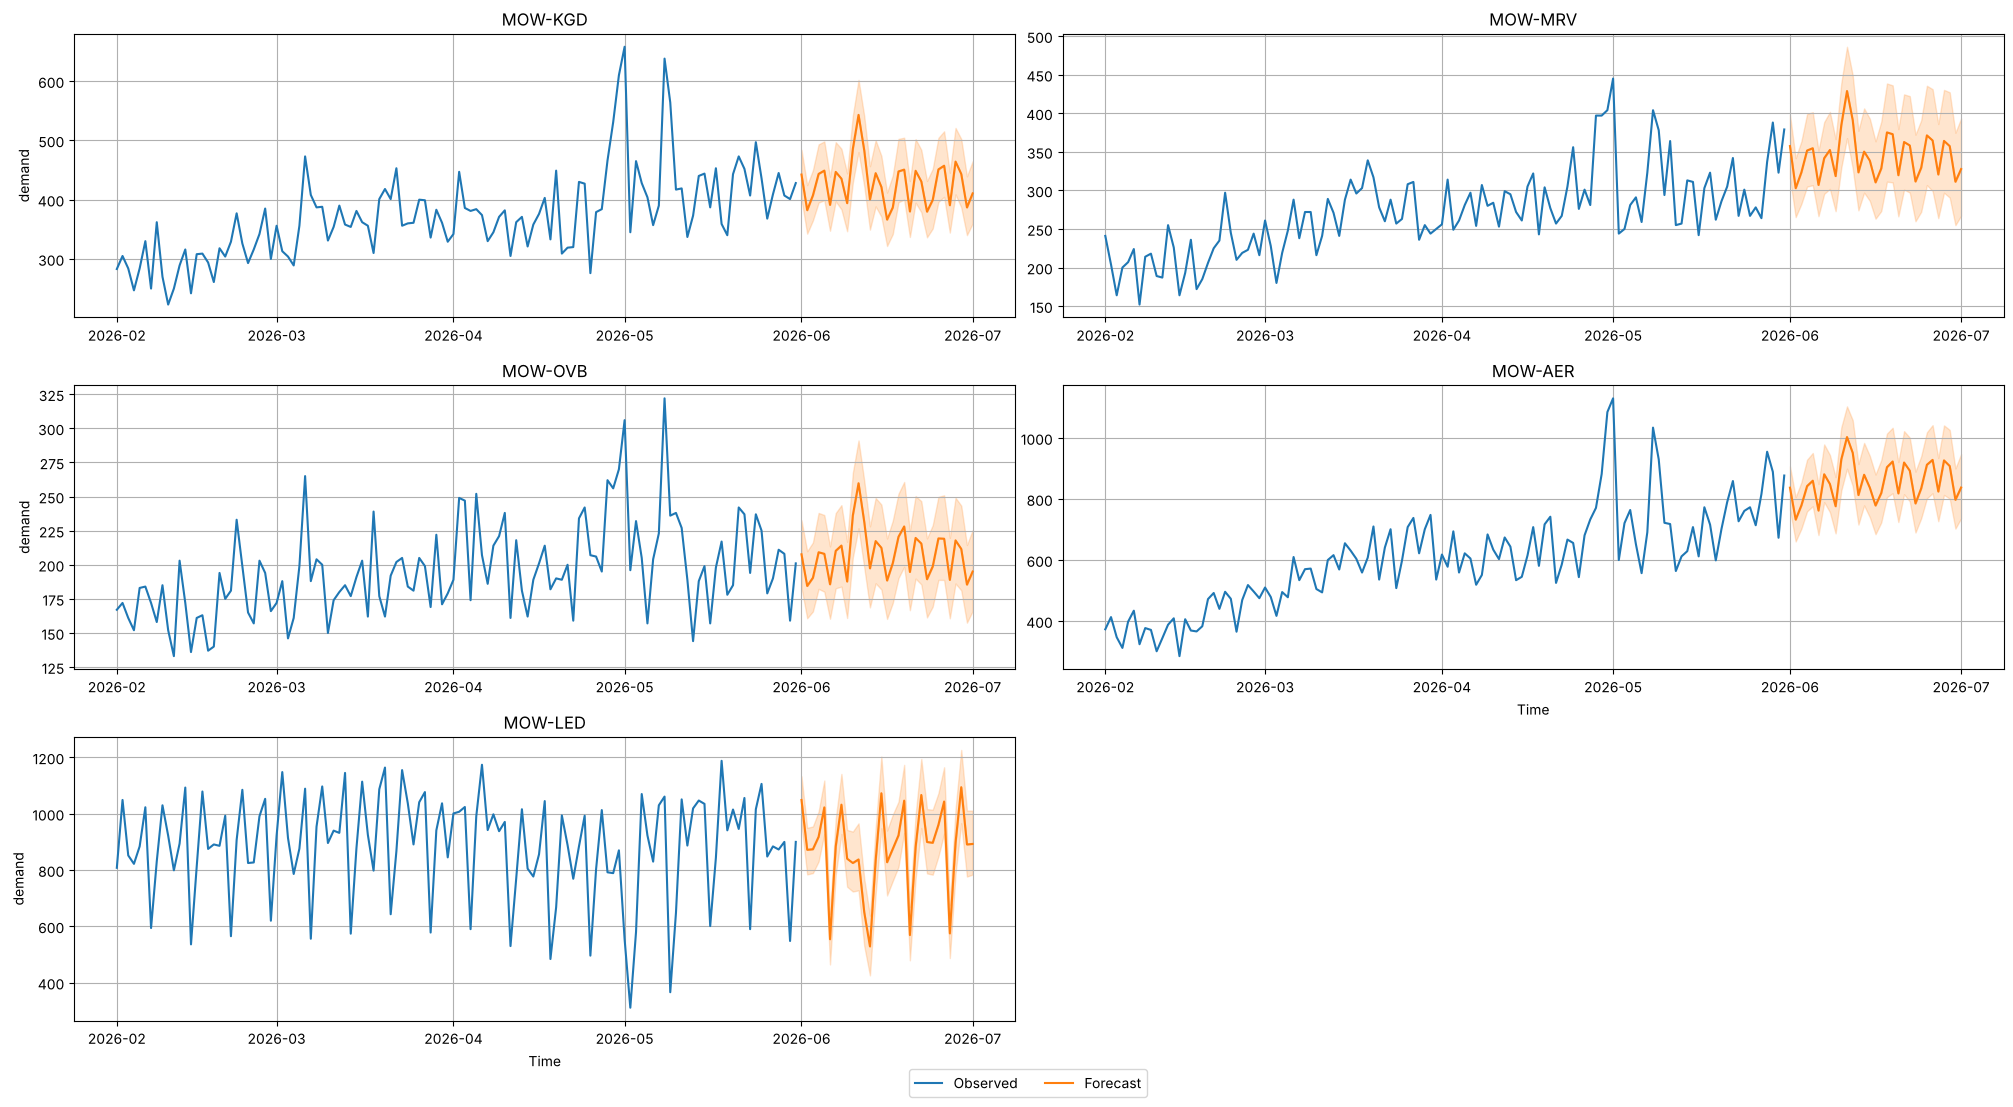

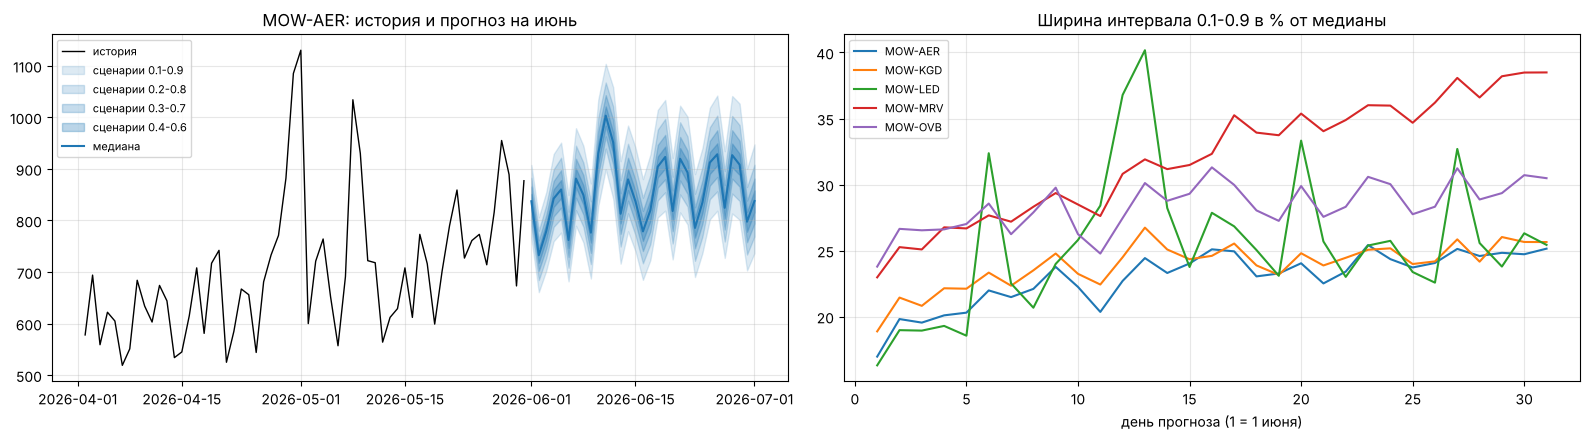

Средняя ширина интервала 0.1-0.9 (в % от медианы): первая неделя 23%, последняя неделя 28%


In [11]:
# Ваш код здесь
# Подсказка: predictor.plot(история, прогноз, quantile_levels=[0.1, 0.9], max_history_length=...)
predictor.plot(history_ts, predictions, quantile_levels=[0.1, 0.9], max_history_length=120, max_num_item_ids=5)
plt.show()

# Все 9 сценариев для Москва - Сочи и ширина интервала 0.1-0.9 по горизонту прогноза
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.5))
hist = history_ts.loc["MOW-AER"]["demand"].iloc[-60:]
pr = predictions.loc["MOW-AER"]
ax1.plot(hist.index, hist, color="k", lw=1, label="история")
for lo, hi, alpha in [("0.1", "0.9", 0.15), ("0.2", "0.8", 0.2), ("0.3", "0.7", 0.25), ("0.4", "0.6", 0.3)]:
    ax1.fill_between(pr.index, pr[lo], pr[hi], color="C0", alpha=alpha, label=f"сценарии {lo}-{hi}")
ax1.plot(pr.index, pr["0.5"], color="C0", label="медиана")
ax1.set_title("MOW-AER: история и прогноз на июнь")
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

width = ((predictions["0.9"] - predictions["0.1"]) / predictions["0.5"]).rename("ширина")
width = width.reset_index()
width["день прогноза"] = width.groupby("item_id").cumcount() + 1
for r, g in width.groupby("item_id"):
    ax2.plot(g["день прогноза"], g["ширина"] * 100, label=r)
ax2.set_title("Ширина интервала 0.1-0.9 в % от медианы")
ax2.set_xlabel("день прогноза (1 = 1 июня)")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Средняя ширина интервала 0.1-0.9 (в % от медианы): первая неделя "
      f"{width[width['день прогноза'] <= 7]['ширина'].mean():.0%}, последняя неделя "
      f"{width[width['день прогноза'] > 24]['ширина'].mean():.0%}")

**Ваш ответ:** Как вам прогноз визуально? Похож ли он на историю? Почему интервал расширяется со временем?

**Прогноз выглядит правдоподобно и похож на историю:**
- сохраняется недельный ритм: на Москве - Петербурге провалы по субботам (~550-600) и пики по понедельникам и пятницам (~1050), на туристических маршрутах - пятница/воскресенье выше середины недели;
- уровень совпадает с последними неделями и с прошлым годом: медиана июньского спроса на Сочи 856 (июнь 2025 - 859), Калининград 428 (405), Новосибирск 208 (207), Минеральные Воды 346 (307, маршрут растёт);
- видны календарные эффекты из признаков: пик перед 12 июня (10-11 июня) на туристических маршрутах (Сочи до ~1000, Калининград ~545) и провал на деловом Петербурге 12-13 июня (650 и 529);
- прогноз глаже истории: медиана не повторяет случайные дневные колебания, они «живут» внутри интервала. Непредсказуемые события вроде закрытия аэропорта в июле 2023 модель, конечно, не предвидит.

**Почему интервал расширяется.** Чем дальше от последнего известного дня, тем больше накапливается неопределённость: в первый день модель точно знает текущий уровень спроса, а за месяц он может уйти из-за тренда, погоды, конкурентов, экономики, и ошибки по дням складываются. Ширина интервала 0.1-0.9 растёт с ~23% медианы в первую неделю до ~28% в последнюю. Сильнее всего - у Минеральных Вод (до ~38%): у этого маршрута самая короткая история, и модель в нём менее уверена. Расширение умеренное, потому что у рядов сильная и устойчивая недельная и годовая сезонность. Всплески ширины на графике у Петербурга - это субботы и праздники, когда медиана маленькая и относительная ширина растёт.

## Задание 7. Как из прогноза спроса получается цена

Обязательно запустите все ячейки этого задания: в конце получится файл с прогнозом спроса и ценами, который понадобится
в части кейса Разработка.

В этом задании ничего писать не нужно, весь код уже готов. Здесь мы разберём, как сервис по вашему прогнозу спроса
подбирает цену билета.

### 7.1. Цена для одного рейса: перебор

Возьмём один рейс - Москва - Сочи, 12 июня - и медианный прогноз спроса для него (квантиль 0.5). Это спрос
**при базовой цене**. Если цену изменить, спрос тоже изменится:

```
спрос(цена) = прогноз спроса − чувствительность × (цена − базовая цена)
```

Например, у Сочи чувствительность 0.141: если поднять цену на 1 000 ₽, лететь захотят примерно на 141 человека меньше.

Продать больше билетов, чем мест в самолёте, нельзя:

```
продано = min(спрос(цена), мест в самолёте)
```

А прибыль - это то, что остаётся с каждого билета после расходов, умноженное на число проданных билетов:

```
прибыль = (цена − расходы на пассажира) × продано
```

Почему у прибыли есть максимум:
- **слишком низкая цена** - билеты раскупят, но с каждого мы заработаем мало;
- **слишком высокая цена** - с каждого билета заработаем много, но покупателей почти не останется.

Лучшая цена где-то посередине. Чтобы её найти, переберём все цены с шагом 100 ₽ и выберем ту, при которой прибыль
наибольшая.

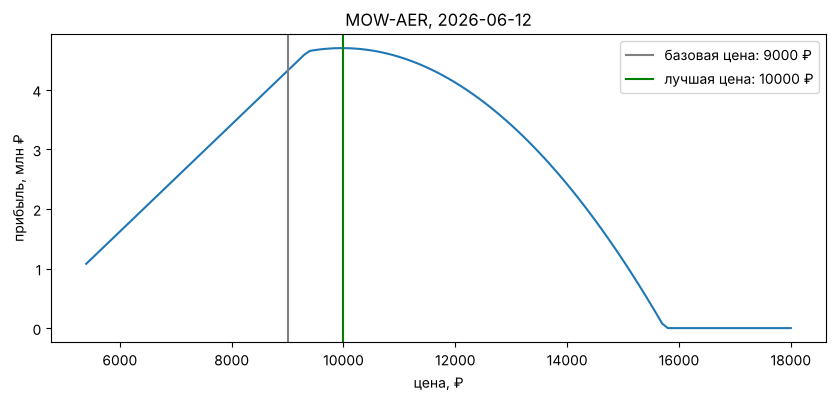

In [12]:
schedule = pd.read_csv(DATA_DIR + "schedule.csv", parse_dates=["date"])

route, day = "MOW-AER", pd.Timestamp("2026-06-12")
info = routes[routes["route"] == route].iloc[0]                                   # параметры маршрута
seats = schedule[(schedule["route"] == route) & (schedule["date"] == day)]["seats"].iloc[0]
demand_base = predictions.loc[(route, day), "0.5"]                                # медианный прогноз спроса

prices = np.arange(info["price_min"], info["price_max"] + 1, 100)                # все цены с шагом 100 ₽
demand = np.maximum(0, demand_base - info["price_sensitivity"] * (prices - info["base_price"]))
sold = np.minimum(demand, seats)
profit = (prices - info["cost_per_passenger"]) * sold
best_price = prices[profit.argmax()]

plt.figure(figsize=(10, 4))
plt.plot(prices, profit / 1e6)
plt.axvline(info["base_price"], color="gray", label=f"базовая цена: {info['base_price']} ₽")
plt.axvline(best_price, color="green", label=f"лучшая цена: {best_price} ₽")
plt.xlabel("цена, ₽"); plt.ylabel("прибыль, млн ₽"); plt.title(f"{route}, {day.date()}")
plt.legend(); plt.show()

### 7.2. Та же цена - по формуле

Перебирать цены не обязательно: лучшую цену можно посчитать сразу, школьной математикой.

**Пока мест хватает**, прибыль зависит от цены как парабола:

```
прибыль(цена) = (цена − расходы) × (прогноз − чувствительность × (цена − базовая цена))
```

Она обращается в ноль в двух точках:
- когда цена равна расходам - с билета ничего не зарабатываем;
- когда цена так высока, что желающих не остаётся: `базовая цена + прогноз / чувствительность`.

Вершина параболы лежит ровно посередине между этими точками:

```
вершина = (расходы + базовая цена + прогноз / чувствительность) / 2
```

**Если желающих больше, чем мест**, цену выгодно поднимать, пока самолёт не начнёт пустеть: всё равно продадим все
места, но дороже. Цена, при которой самолёт ровно заполняется:

```
цена_полного_самолёта = базовая цена + (прогноз − мест) / чувствительность
```

**Лучшая цена** - большая из этих двух, но не выходящая за допустимый диапазон от `price_min` до `price_max`. Проверим,
что формула даёт то же, что и перебор (перебор шёл с шагом 100 ₽, поэтому совпадение - с точностью до 100 ₽).

In [13]:
def optimal_price(demand_base, info, seats):
    """Лучшая цена для одного сценария спроса - по формуле, без перебора."""
    b, p0, cost = info["price_sensitivity"], info["base_price"], info["cost_per_passenger"]
    top_of_parabola = (cost + p0 + demand_base / b) / 2       # вершина параболы (мест хватает)
    full_plane = p0 + (demand_base - seats) / b                # самолёт заполнен ровно
    price = max(top_of_parabola, full_plane)
    return min(max(price, info["price_min"]), info["price_max"])   # не выходим за допустимый диапазон

print("перебор:", best_price, "₽")
print("формула:", round(optimal_price(demand_base, info, seats)), "₽")

перебор: 10000 ₽
формула: 9973 ₽


### 7.3. От квантилей спроса - к распределению цены

До сих пор мы считали цену только для медианного прогноза (квантиль 0.5). Но модель выдаёт 9 сценариев спроса,
от пессимистичного 0.1 до оптимистичного 0.9. Посчитаем лучшую цену для каждого из них.

Чем больше спрос, тем выше лучшая цена. Поэтому из 9 сценариев спроса получается 9 сценариев цены - это и есть
**распределение цены**, о котором шла речь в начале:
- если цены в разных сценариях близки, модель уверена и цену можно ставить смело;
- если разброс большой, на рейс стоит посмотреть внимательнее и выбрать менее рискованную цену.

Для каждого сценария посчитаем, сколько билетов продадим по лучшей цене и какой будет прибыль. Для сравнения - прибыль,
если оставить базовую цену.

In [14]:
QUANTILES = ["0.1", "0.2", "0.3", "0.4", "0.5", "0.6", "0.7", "0.8", "0.9"]

rows = []
for q in QUANTILES:
    d = predictions.loc[(route, day), q]                          # спрос при базовой цене в этом сценарии
    price = optimal_price(d, info, seats)
    sold_q = min(max(0, d - info["price_sensitivity"] * (price - info["base_price"])), seats)
    sold_base = min(d, seats)                                     # продажи, если оставить базовую цену
    rows.append({
        "квантиль": q,
        "спрос при базовой цене": round(d),
        "лучшая цена, ₽": round(price),
        "продано": round(sold_q),
        "прибыль, млн ₽": round((price - info["cost_per_passenger"]) * sold_q / 1e6, 2),
        "прибыль при базовой цене, млн ₽": round((info["base_price"] - info["cost_per_passenger"]) * sold_base / 1e6, 2),
    })
pd.DataFrame(rows)

,квантиль,спрос при базовой цене,"лучшая цена, ₽",продано,"прибыль, млн ₽","прибыль при базовой цене, млн ₽"
0,0.1,842,9587,760,4.09,4.04
1,0.2,881,9723,779,4.30,4.23
2,0.3,909,9822,793,4.46,4.32
3,0.4,929,9894,803,4.57,4.32
4,0.5,951,9973,814,4.70,4.32
5,0.6,971,10045,824,4.82,4.32
6,0.7,995,10130,836,4.96,4.32
7,0.8,1021,10220,849,5.11,4.32
8,0.9,1058,10353,868,5.34,4.32


### 7.4. Все рейсы и файл для сервиса

Теперь посчитаем то же самое для всех маршрутов и всех дней июня. Для каждого рейса и каждого из 9 сценариев получим
спрос при базовой цене, лучшую цену и спрос при лучшей цене. Результат сохраним в файл `my_forecast.csv`, его и нужно будет использовать в части Разработка.

Колонки файла:

| колонка | что означает |
|---|---|
| `route` | код маршрута |
| `date` | дата рейса |
| `seats` | сколько мест в самолётах |
| `0.1_base_demand` … `0.9_base_demand` | спрос при базовой цене в каждом сценарии |
| `0.1_price` … `0.9_price` | лучшая цена в каждом сценарии, ₽ |
| `0.1_price_demand` … `0.9_price_demand` | спрос при лучшей цене (без учёта ограничения по местам) |

In [15]:
rows = []
for (route_i, day_i), forecast_row in predictions.iterrows():          # по одной строке на маршрут и день
    info_i = routes[routes["route"] == route_i].iloc[0]
    seats_i = schedule[(schedule["route"] == route_i) & (schedule["date"] == day_i)]["seats"].iloc[0]
    row = {"route": route_i, "date": day_i.strftime("%Y-%m-%d"), "seats": seats_i}
    for q in QUANTILES:
        d = forecast_row[q]
        price = optimal_price(d, info_i, seats_i)
        row[f"{q}_base_demand"] = round(d)                                                        # спрос при базовой цене
        row[f"{q}_price"] = round(price)                                                          # лучшая цена
        row[f"{q}_price_demand"] = round(max(0, d - info_i["price_sensitivity"] * (price - info_i["base_price"])))
    rows.append(row)

result = pd.DataFrame(rows)
result.to_csv("my_forecast.csv", index=False)
result.head()

,route,date,seats,0.1_base_demand,0.1_price,0.1_price_demand,0.2_base_demand,0.2_price,0.2_price_demand,0.3_base_demand,...,0.6_price_demand,0.7_base_demand,0.7_price,0.7_price_demand,0.8_base_demand,0.8_price,0.8_price_demand,0.9_base_demand,0.9_price,0.9_price_demand
0,MOW-AER,2026-06-01,900,765,9314,721,790,9400,733,808,...,764,866,9670,771,883,9730,780,908,9818,792
1,MOW-AER,2026-06-02,900,661,8944,669,684,9027,681,702,...,712,761,9300,719,780,9367,728,806,9458,741
2,MOW-AER,2026-06-03,900,703,9091,690,727,9179,702,746,...,736,810,9472,743,830,9542,753,855,9631,766
3,MOW-AER,2026-06-04,900,760,9294,718,788,9393,732,808,...,769,877,9709,777,899,9788,788,929,9894,803
4,MOW-AER,2026-06-05,900,776,9353,727,804,9449,740,825,...,778,897,9782,787,922,9868,799,951,9972,814


Посмотрим на один маршрут целиком. Сверху - спрос при базовой цене и спрос при лучшей цене вместе с числом мест
в самолётах, снизу - лучшая цена и базовая цена. Видно, как цена следует за спросом: где спрос высокий, цену поднимаем,
и желающих становится меньше.

**Результат задания:** запущенные ячейки и файл `my_forecast.csv`.

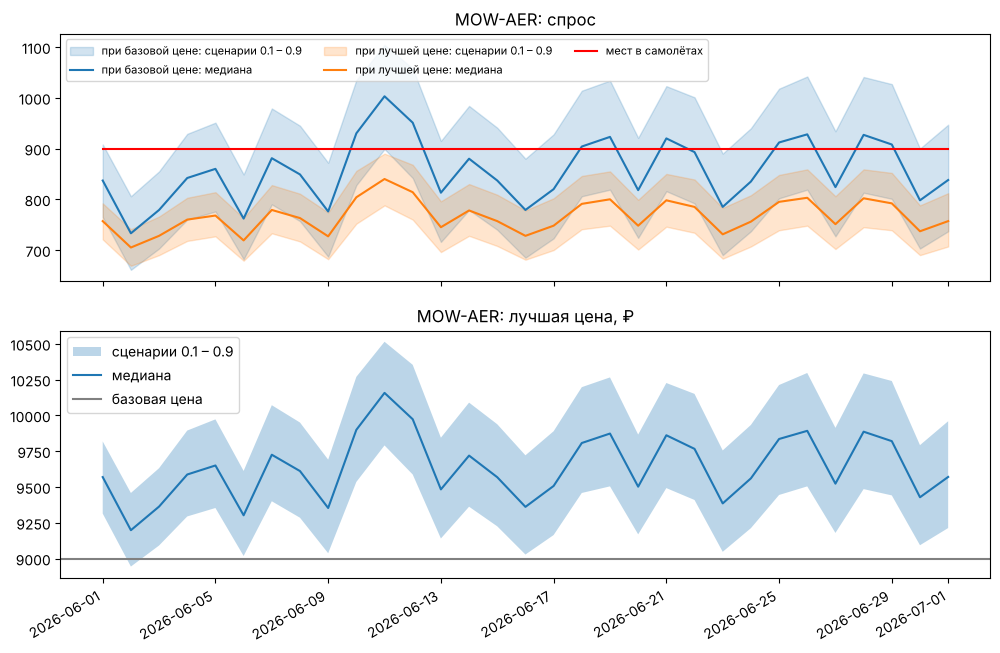

In [16]:
one = result[result["route"] == "MOW-AER"]
dates = pd.to_datetime(one["date"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.fill_between(dates, one["0.1_base_demand"], one["0.9_base_demand"], color="C0", alpha=0.2,
                 label="при базовой цене: сценарии 0.1 – 0.9")
ax1.plot(dates, one["0.5_base_demand"], color="C0", label="при базовой цене: медиана")
ax1.fill_between(dates, one["0.1_price_demand"], one["0.9_price_demand"], color="C1", alpha=0.2,
                 label="при лучшей цене: сценарии 0.1 – 0.9")
ax1.plot(dates, one["0.5_price_demand"], color="C1", label="при лучшей цене: медиана")
ax1.plot(dates, one["seats"], color="red", label="мест в самолётах")
ax1.set_title("MOW-AER: спрос"); ax1.legend(fontsize=8, ncol=3)

ax2.fill_between(dates, one["0.1_price"], one["0.9_price"], alpha=0.3, label="сценарии 0.1 – 0.9")
ax2.plot(dates, one["0.5_price"], label="медиана")
ax2.axhline(routes[routes["route"] == "MOW-AER"]["base_price"].iloc[0], color="gray", label="базовая цена")
ax2.set_title("MOW-AER: лучшая цена, ₽"); ax2.legend()
fig.autofmt_xdate()                                    # наклоняем подписи дат, чтобы не наезжали
plt.show()

## Готово!

Сдайте:
1. этот ноутбук с вашим кодом и ответами на вопросы;
2. файл `my_forecast.csv` из задания 7 - используйте его в части кейса Разработка.